# Regime Detection Results — For Paper
**LEAF Framework · Section 3.5: Market Regime Detection**

3-state Gaussian HMM · Features: `port_ret`, `port_vol20`, `port_ret_ma20`  
Train: 2013-01-02 → 2022-06-30 · Test: 2022-07-01 → 2025-12-31

In [1]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from pathlib import Path
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.dpi': 150,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'legend.fontsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

ROOT = Path('../../')
FEAT_PATH = ROOT / 'data/processed/v2/features_all.csv'
FIG_DIR   = ROOT / 'notebooks/eda/figures'
FIG_DIR.mkdir(exist_ok=True)

TRAIN_END   = '2022-06-30'
RANDOM_SEED = 42
REGIME_COLORS = {'Bull': '#2ecc71', 'Sideways': '#f39c12', 'Bear': '#e74c3c'}

print('Setup done. ROOT:', ROOT.resolve())

Setup done. ROOT: D:\fm-forecasting


## 0 · Load Data & Run HMM
Re-compute regime inline so results are always consistent with latest code.

In [2]:
# Load feature data
df = pd.read_csv(FEAT_PATH, parse_dates=['Date'])
print(f'features_all: {df.shape}  |  tickers: {df["ticker"].nunique()}')

# Build equal-weight portfolio series
port = (
    df.groupby('Date')[['ret_1d', 'vol_20d']]
    .mean()
    .rename(columns={'ret_1d': 'port_ret', 'vol_20d': 'port_vol20'})
)
port.index = pd.to_datetime(port.index)
port = port.sort_index()
port.index.name = 'Date'

port['port_vol60']     = port['port_ret'].rolling(60).std()
port['port_vol_ratio'] = port['port_vol20'] / port['port_vol60'].replace(0, np.nan)
port['port_ret_ma20']  = port['port_ret'].rolling(20).mean()

port = port.dropna(subset=['port_ret', 'port_vol20', 'port_ret_ma20'])
print(f'Portfolio after dropna: {len(port)} days  |  {port.index.min().date()} → {port.index.max().date()}')

features_all: (48642, 42)  |  tickers: 15
Portfolio after dropna: 3225 days  |  2013-01-30 → 2025-12-31


In [3]:
# Fit 3-state HMM on Train set (3 features)
features = ['port_ret', 'port_vol20', 'port_ret_ma20']
train_mask = port.index <= TRAIN_END
X_full = port[features].values

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_full[train_mask])
X_full_scaled  = scaler.transform(X_full)

model = GaussianHMM(
    n_components=3, covariance_type='full',
    n_iter=200, random_state=RANDOM_SEED, tol=1e-4,
)
model.fit(X_train_scaled)
states_arr = model.predict(X_full_scaled)

print(f'Converged: {model.monitor_.converged}')
print(f'Log-likelihood (train): {model.score(X_train_scaled):.2f}')

Converged: True
Log-likelihood (train): -6891.67


In [4]:
# Label states by Return (Bull=max return, Bear=min return)
state_ret = {}
state_vol = {}
for s in range(3):
    mask = states_arr == s
    ret = port['port_ret'].values[mask].mean()
    vol = port['port_ret'].values[mask].std()
    state_ret[s] = ret
    state_vol[s] = vol

sorted_states = sorted(state_ret.keys(), key=lambda s: state_ret[s], reverse=True)
label_map = {sorted_states[0]: 'Bull', sorted_states[1]: 'Sideways', sorted_states[2]: 'Bear'}

# Step 1: raw Viterbi labels (economically correct)
raw_labels = pd.Series([label_map[s] for s in states_arr], index=port.index)

# Step 2: 21-day centered majority vote on STRING labels (for visualization)
# - HMM gán nhãn theo volatility ngày, không phải trend dài hạn
# - 21 ngày đủ để giữ COVID crash (~1 tháng) và bond crisis, loại Bear noise ngắn
SMOOTH_WIN = 21
label_to_int = {'Bull': 0, 'Sideways': 1, 'Bear': 2}
int_to_label  = {0: 'Bull', 1: 'Sideways', 2: 'Bear'}

port['regime'] = (
    raw_labels.map(label_to_int)
    .rolling(window=SMOOTH_WIN, min_periods=max(1, SMOOTH_WIN // 2), center=True)
    .apply(lambda x: pd.Series(x).mode().iloc[0])
    .astype(int)
    .map(int_to_label)
    .fillna(raw_labels)
)

print('=== RAW state stats (label basis, not smoothed) ===')
for s in sorted_states:
    mask = states_arr == s
    ret_ann = port['port_ret'].values[mask].mean() * 252 * 100
    vol_ann = port['port_ret'].values[mask].std() * np.sqrt(252) * 100
    print(f'  State {s} → {label_map[s]:8s} | ret_ann={ret_ann:+.2f}% | vol_ann={vol_ann:.2f}% | {mask.mean()*100:.1f}%')

print(f'\n=== SMOOTHED ({SMOOTH_WIN}d centered majority) — used in plots ===')
for lbl in ['Bull', 'Sideways', 'Bear']:
    mask = (port['regime'] == lbl).values
    ret_ann = port['port_ret'].values[mask].mean() * 252 * 100
    vol_ann = port['port_ret'].values[mask].std() * np.sqrt(252) * 100
    print(f'  {lbl:8s}: n={mask.sum():4d} ({mask.mean()*100:.1f}%) | ret_ann={ret_ann:+.2f}% | vol_ann={vol_ann:.2f}%')

=== RAW state stats (label basis, not smoothed) ===
  State 1 → Bull     | ret_ann=+22.50% | vol_ann=18.85% | 31.5%
  State 2 → Sideways | ret_ann=+21.97% | vol_ann=11.78% | 48.8%
  State 0 → Bear     | ret_ann=-15.56% | vol_ann=33.27% | 19.7%

=== SMOOTHED (21d centered majority) — used in plots ===
  Bull    : n= 966 (30.0%) | ret_ann=+17.25% | vol_ann=19.22%
  Sideways: n=1596 (49.5%) | ret_ann=+22.32% | vol_ann=11.93%
  Bear    : n= 663 (20.6%) | ret_ann=-7.19% | vol_ann=32.51%


---
## Section 1 · Regime Statistics Table
*(Paper: Table 3.X — Regime characteristics)*

In [5]:
rows = []
for lbl in ['Bull', 'Sideways', 'Bear']:
    mask = port['regime'] == lbl
    r = port.loc[mask, 'port_ret']
    rows.append({
        'Regime':           lbl,
        'N days':           int(mask.sum()),
        'Share (%)':        round(mask.mean() * 100, 1),
        'Ann. Return (%)':  round(r.mean() * 252 * 100, 2),
        'Ann. Volatility (%)': round(r.std() * np.sqrt(252) * 100, 2),
        'Sharpe':           round((r.mean() * 252) / (r.std() * np.sqrt(252) + 1e-9), 3),
        'Max Drawdown (%)': round(
            ((r + 1).cumprod() / (r + 1).cumprod().cummax() - 1).min() * 100, 2
        ),
    })

stats = pd.DataFrame(rows).set_index('Regime')
print(stats.to_string())
stats

          N days  Share (%)  Ann. Return (%)  Ann. Volatility (%)  Sharpe  Max Drawdown (%)
Regime                                                                                     
Bull         966       30.0            17.25                19.23   0.897            -29.53
Sideways    1596       49.5            22.32                11.93   1.870            -19.69
Bear         663       20.6            -7.19                32.54  -0.221            -51.76


,N days,Share (%),Ann. Return (%),Ann. Volatility (%),Sharpe,Max Drawdown (%)
Regime,,,,,,
Bull,966,30.0,17.25,19.23,0.897,-29.53
Sideways,1596,49.5,22.32,11.93,1.870,-19.69
Bear,663,20.6,-7.19,32.54,-0.221,-51.76


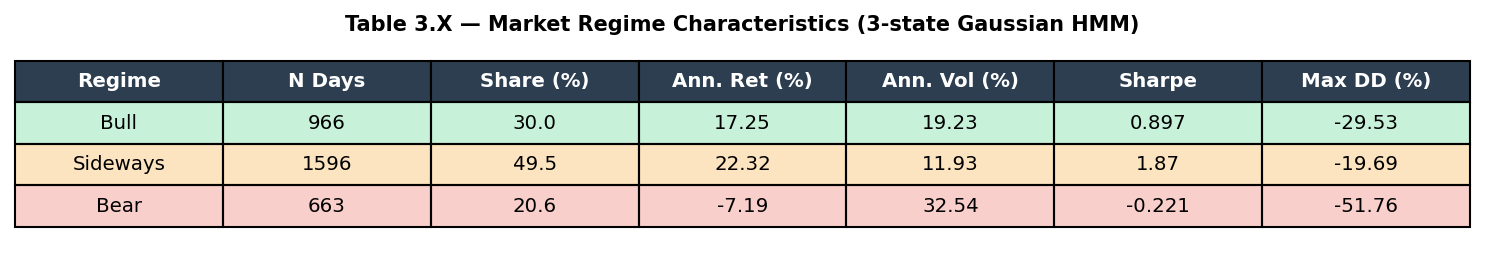

In [6]:
# Styled table for paper
fig, ax = plt.subplots(figsize=(10, 1.8))
ax.axis('off')

col_labels = ['Regime', 'N Days', 'Share (%)', 'Ann. Ret (%)', 'Ann. Vol (%)', 'Sharpe', 'Max DD (%)']
cell_data = []
for r in rows:
    cell_data.append([
        r['Regime'], r['N days'], r['Share (%)'],
        r['Ann. Return (%)'], r['Ann. Volatility (%)'],
        r['Sharpe'], r['Max Drawdown (%)']
    ])

row_colors = [[REGIME_COLORS[r[0]] + '44'] * len(col_labels) for r in cell_data]
tbl = ax.table(
    cellText=cell_data, colLabels=col_labels,
    cellLoc='center', loc='center',
    cellColours=row_colors,
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9.5)
tbl.scale(1, 1.8)

# Header style
for j in range(len(col_labels)):
    tbl[0, j].set_facecolor('#2c3e50')
    tbl[0, j].set_text_props(color='white', fontweight='bold')

plt.title('Table 3.X — Market Regime Characteristics (3-state Gaussian HMM)', 
          fontsize=10, fontweight='bold', pad=8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'table_regime_stats.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 2 · Regime Timeline
*(Paper: Figure 3.X — VN30 portfolio with regime background)*

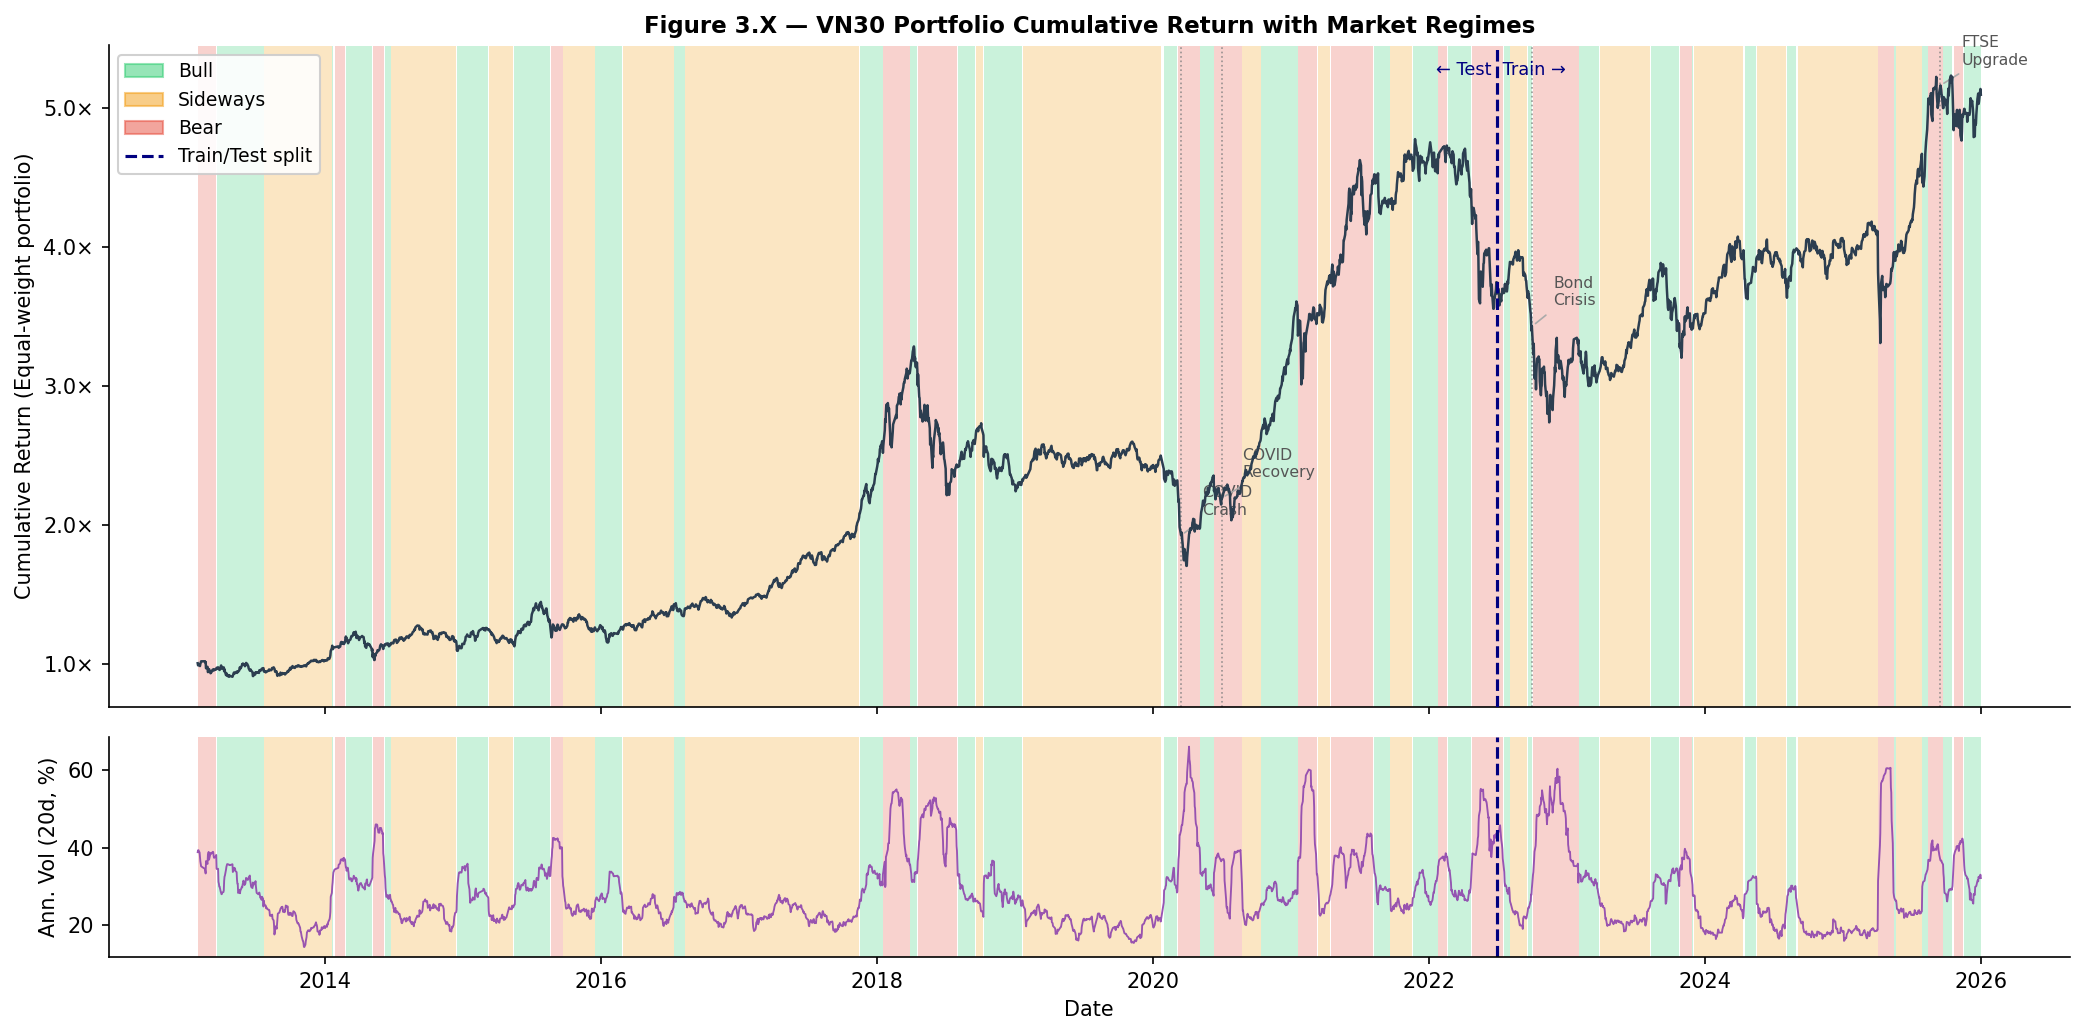

Saved: fig_regime_timeline.png


In [7]:
# Compute cumulative return for the portfolio
port['cum_ret'] = (1 + port['port_ret']).cumprod()

special_events = {
    'COVID\nCrash':   '2020-03-16',
    'COVID\nRecovery': '2020-07-01',
    'Bond\nCrisis':   '2022-10-01',
    'FTSE\nUpgrade':  '2025-09-15',
}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1]})

# ── Cumulative return with regime shading ──
regime_series = port['regime']
dates = port.index

def shade_regimes(ax, port, col='regime'):
    r = port[col]
    i = 0
    while i < len(r):
        label = r.iloc[i]
        j = i + 1
        while j < len(r) and r.iloc[j] == label:
            j += 1
        ax.axvspan(r.index[i], r.index[j-1], alpha=0.25,
                   color=REGIME_COLORS[label], linewidth=0)
        i = j

shade_regimes(ax1, port)
ax1.plot(port.index, port['cum_ret'], color='#2c3e50', linewidth=1.2, zorder=5)
ax1.axvline(pd.Timestamp(TRAIN_END), color='navy', linewidth=1.5, 
            linestyle='--', zorder=6, label=f'Train/Test split ({TRAIN_END})')
ax1.text(pd.Timestamp(TRAIN_END), ax1.get_ylim()[1] * 0.98,
         ' Train →', ha='left', va='top', fontsize=8.5, color='navy')
ax1.text(pd.Timestamp(TRAIN_END), ax1.get_ylim()[1] * 0.98,
         '← Test ', ha='right', va='top', fontsize=8.5, color='navy')

# Special event annotations
for ev_name, ev_date in special_events.items():
    ts = pd.Timestamp(ev_date)
    if ts in port.index or (ts > port.index.min() and ts < port.index.max()):
        ax1.axvline(ts, color='gray', linewidth=0.8, linestyle=':', alpha=0.8)
        y_pos = port['cum_ret'].loc[:ts].iloc[-1] if ts <= port.index.max() else port['cum_ret'].iloc[-1]
        ax1.annotate(ev_name, xy=(ts, y_pos), xytext=(10, 10),
                     textcoords='offset points', fontsize=7.5, color='#555',
                     arrowprops=dict(arrowstyle='-', color='#aaa', lw=0.8))

patches = [mpatches.Patch(color=REGIME_COLORS[l], alpha=0.5, label=l)
           for l in ['Bull', 'Sideways', 'Bear']]
ax1.legend(handles=patches + [plt.Line2D([0],[0],color='navy',linestyle='--',label='Train/Test split')],
           loc='upper left', framealpha=0.9)
ax1.set_ylabel('Cumulative Return (Equal-weight portfolio)')
ax1.set_title('Figure 3.X — VN30 Portfolio Cumulative Return with Market Regimes', fontweight='bold')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:.1f}×'))

# ── Volatility with regime shading ──
shade_regimes(ax2, port)
ax2.plot(port.index, port['port_vol20'] * np.sqrt(252) * 100, 
         color='#8e44ad', linewidth=0.9, alpha=0.9)
ax2.axvline(pd.Timestamp(TRAIN_END), color='navy', linewidth=1.5, linestyle='--')
ax2.set_ylabel('Ann. Vol (20d, %)')
ax2.set_xlabel('Date')

plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_regime_timeline.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_regime_timeline.png')

---
## Section 3 · Yearly Regime Distribution
*(Paper: Figure 3.X — Stacked bar by year)*

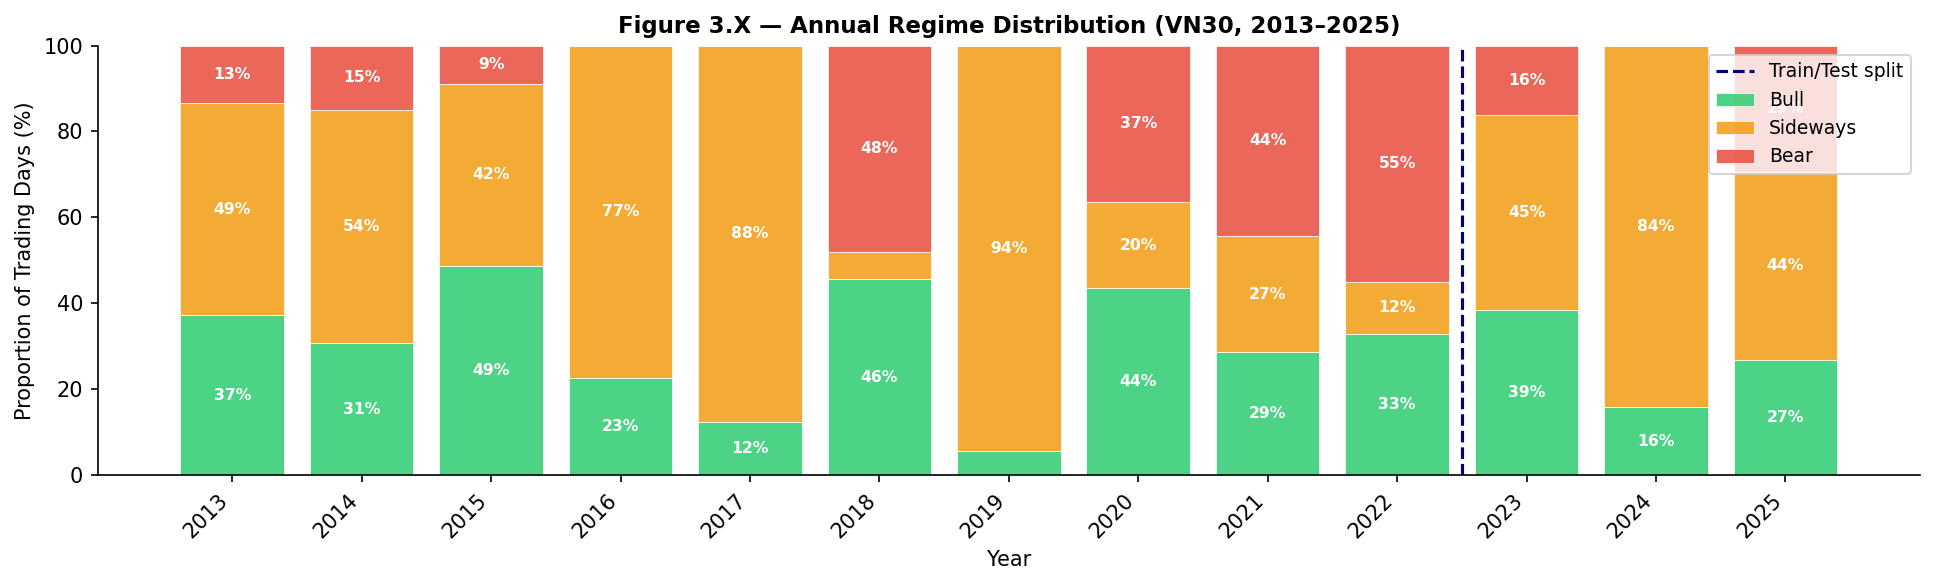

In [8]:
port['year'] = port.index.year
yearly = port.groupby(['year', 'regime']).size().unstack(fill_value=0)
for lbl in ['Bull', 'Sideways', 'Bear']:
    if lbl not in yearly.columns:
        yearly[lbl] = 0
yearly = yearly[['Bull', 'Sideways', 'Bear']]
yearly_pct = yearly.div(yearly.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(13, 4))

bottom = np.zeros(len(yearly_pct))
for lbl in ['Bull', 'Sideways', 'Bear']:
    vals = yearly_pct[lbl].values
    bars = ax.bar(yearly_pct.index, vals, bottom=bottom,
                  color=REGIME_COLORS[lbl], label=lbl, alpha=0.85, edgecolor='white', linewidth=0.4)
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 8:
            ax.text(yearly_pct.index[i], b + v/2, f'{v:.0f}%',
                    ha='center', va='center', fontsize=7.5, color='white', fontweight='bold')
    bottom += vals

ax.axvline(2022.5, color='navy', linewidth=1.5, linestyle='--', label='Train/Test split')
ax.set_xlabel('Year')
ax.set_ylabel('Proportion of Trading Days (%)')
ax.set_title('Figure 3.X — Annual Regime Distribution (VN30, 2013–2025)', fontweight='bold')
ax.set_xticks(yearly_pct.index)
ax.set_xticklabels(yearly_pct.index, rotation=45, ha='right')
ax.set_ylim(0, 100)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_regime_yearly.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 4 · Return Distribution per Regime
*(Paper: Figure 3.X — Distribution of daily returns by regime)*

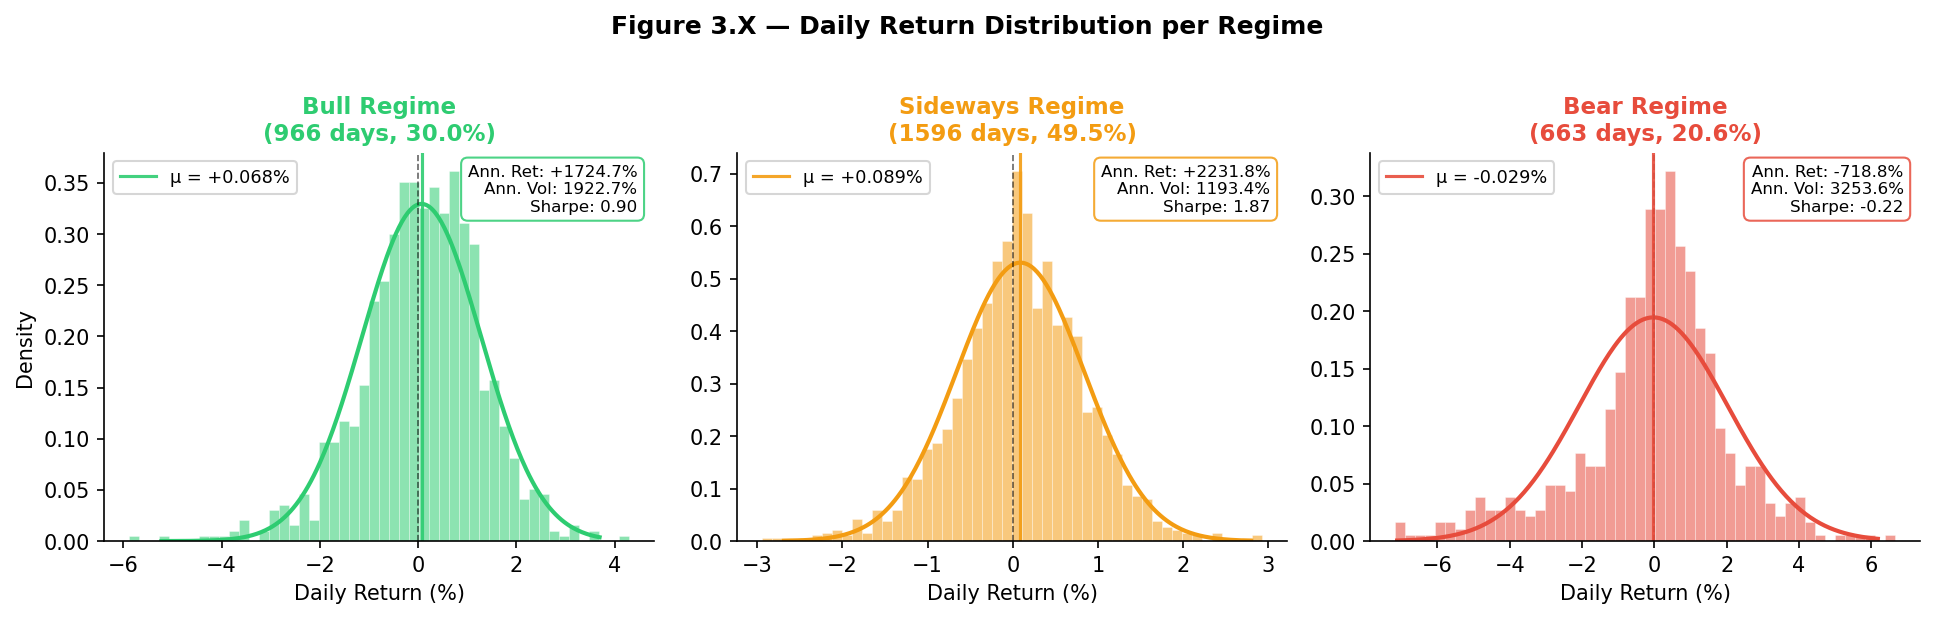

In [9]:
from scipy.stats import norm

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=False)

for ax, lbl in zip(axes, ['Bull', 'Sideways', 'Bear']):
    r = port.loc[port['regime'] == lbl, 'port_ret'] * 100  # in %
    color = REGIME_COLORS[lbl]
    
    ax.hist(r, bins=50, density=True, color=color, alpha=0.55, edgecolor='white', linewidth=0.3)
    
    # Fitted normal
    mu, sigma = r.mean(), r.std()
    x = np.linspace(r.quantile(0.001), r.quantile(0.999), 300)
    ax.plot(x, norm.pdf(x, mu, sigma), color=color, linewidth=2)
    ax.axvline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.6)
    ax.axvline(mu, color=color, linewidth=1.5, linestyle='-', alpha=0.9,
               label=f'μ = {mu:+.3f}%')
    
    ann_ret = mu * 252
    ann_vol = sigma * np.sqrt(252)
    n_days = len(r)
    ax.set_title(f'{lbl} Regime\n({n_days} days, {n_days/len(port)*100:.1f}%)', 
                 fontweight='bold', color=REGIME_COLORS[lbl])
    ax.set_xlabel('Daily Return (%)')
    ax.set_ylabel('Density' if lbl == 'Bull' else '')
    ax.legend(fontsize=8.5)
    
    textbox = f'Ann. Ret: {ann_ret*100:+.1f}%\nAnn. Vol: {ann_vol*100:.1f}%\nSharpe: {ann_ret/ann_vol:.2f}'
    ax.text(0.97, 0.97, textbox, transform=ax.transAxes,
            ha='right', va='top', fontsize=8, 
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.85, edgecolor=color))

fig.suptitle('Figure 3.X — Daily Return Distribution per Regime', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_regime_return_dist.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 5 · Transition Matrix
*(Regime persistence — probability of staying in / switching regime)*


Average regime duration (consecutive days):
  Bull    : p(stay)=0.970  →  avg duration ≈ 33.3 days
  Sideways: p(stay)=0.989  →  avg duration ≈ 93.9 days
  Bear    : p(stay)=0.974  →  avg duration ≈ 39.0 days


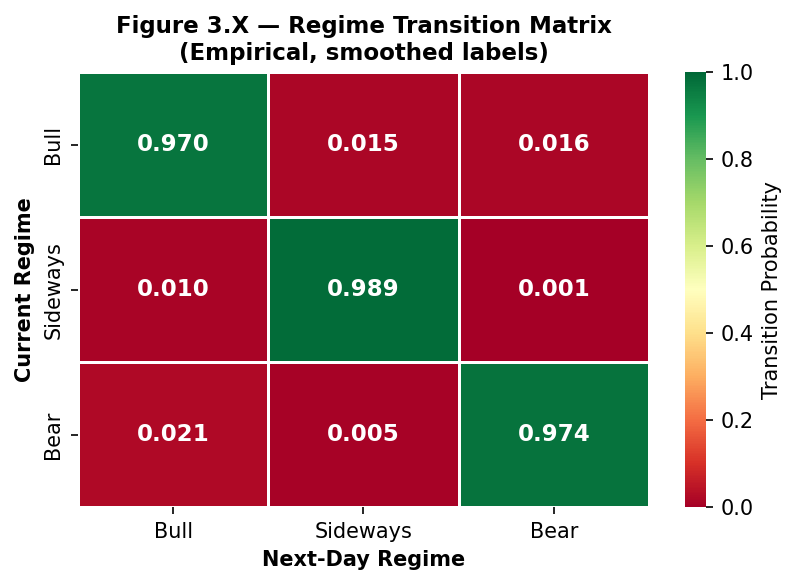

In [10]:
import seaborn as sns

# Compute empirical transition matrix from smoothed labels
reg_seq = port['regime'].values
order = ['Bull', 'Sideways', 'Bear']
trans = pd.DataFrame(0, index=order, columns=order, dtype=float)
for i in range(len(reg_seq) - 1):
    trans.loc[reg_seq[i], reg_seq[i+1]] += 1

# Row-normalize
trans_norm = trans.div(trans.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(
    trans_norm, annot=True, fmt='.3f', cmap='RdYlGn',
    vmin=0, vmax=1, ax=ax, linewidths=0.5, linecolor='white',
    annot_kws={'size': 11, 'weight': 'bold'},
    cbar_kws={'label': 'Transition Probability'},
)
ax.set_xlabel('Next-Day Regime', fontweight='bold')
ax.set_ylabel('Current Regime', fontweight='bold')
ax.set_title('Figure 3.X — Regime Transition Matrix\n(Empirical, smoothed labels)', fontweight='bold')

# Avg duration
print('\nAverage regime duration (consecutive days):')
for lbl in order:
    p_stay = trans_norm.loc[lbl, lbl]
    avg_dur = 1 / (1 - p_stay) if p_stay < 1 else float('inf')
    print(f'  {lbl:8s}: p(stay)={p_stay:.3f}  →  avg duration ≈ {avg_dur:.1f} days')

plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_regime_transition.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 6 · Key Evidence: 2-feature vs 3-feature HMM
*(Paper: justification for adding `port_ret_ma20`)*

In [11]:
# Run 2-feature HMM for comparison
def fit_hmm_variant(port_df, features_list, n_iter=200, seed=42, train_end=TRAIN_END):
    p = port_df.dropna(subset=features_list).copy()
    train_mask = p.index <= train_end
    X = p[features_list].values
    sc = StandardScaler()
    X_tr = sc.fit_transform(X[train_mask])
    X_full = sc.transform(X)
    m = GaussianHMM(n_components=3, covariance_type='full',
                    n_iter=n_iter, random_state=seed, tol=1e-4)
    m.fit(X_tr)
    states = m.predict(X_full)
    # Label by return
    state_ret = {s: p['port_ret'].values[states == s].mean() for s in range(3)}
    srt = sorted(state_ret, key=lambda s: state_ret[s], reverse=True)
    lmap = {srt[0]: 'Bull', srt[1]: 'Sideways', srt[2]: 'Bear'}
    labeled = pd.Series([lmap[s] for s in states], index=p.index)
    # Stats
    rows = []
    for lbl in ['Bull', 'Sideways', 'Bear']:
        mask = labeled == lbl
        r = p.loc[mask, 'port_ret']
        rows.append({
            'Regime': lbl, 'N days': int(mask.sum()),
            'Share (%)': round(mask.mean() * 100, 1),
            'Ann. Ret (%)': round(r.mean() * 252 * 100, 2),
            'Ann. Vol (%)': round(r.std() * np.sqrt(252) * 100, 2),
        })
    return labeled, pd.DataFrame(rows)

states_2feat, stats_2feat = fit_hmm_variant(port, ['port_ret', 'port_vol20'])
states_3feat, stats_3feat = fit_hmm_variant(port, ['port_ret', 'port_vol20', 'port_ret_ma20'])

print('=== 2-feature HMM ===')
print(stats_2feat.to_string(index=False))
print('\n=== 3-feature HMM ===')
print(stats_3feat.to_string(index=False))

=== 2-feature HMM ===
  Regime  N days  Share (%)  Ann. Ret (%)  Ann. Vol (%)
    Bull     977       30.3         29.29         12.23
Sideways     956       29.6         15.89         12.85
    Bear    1292       40.1          2.87         27.57

=== 3-feature HMM ===
  Regime  N days  Share (%)  Ann. Ret (%)  Ann. Vol (%)
    Bull    1016       31.5         22.50         18.86
Sideways    1573       48.8         21.97         11.79
    Bear     636       19.7        -15.56         33.29


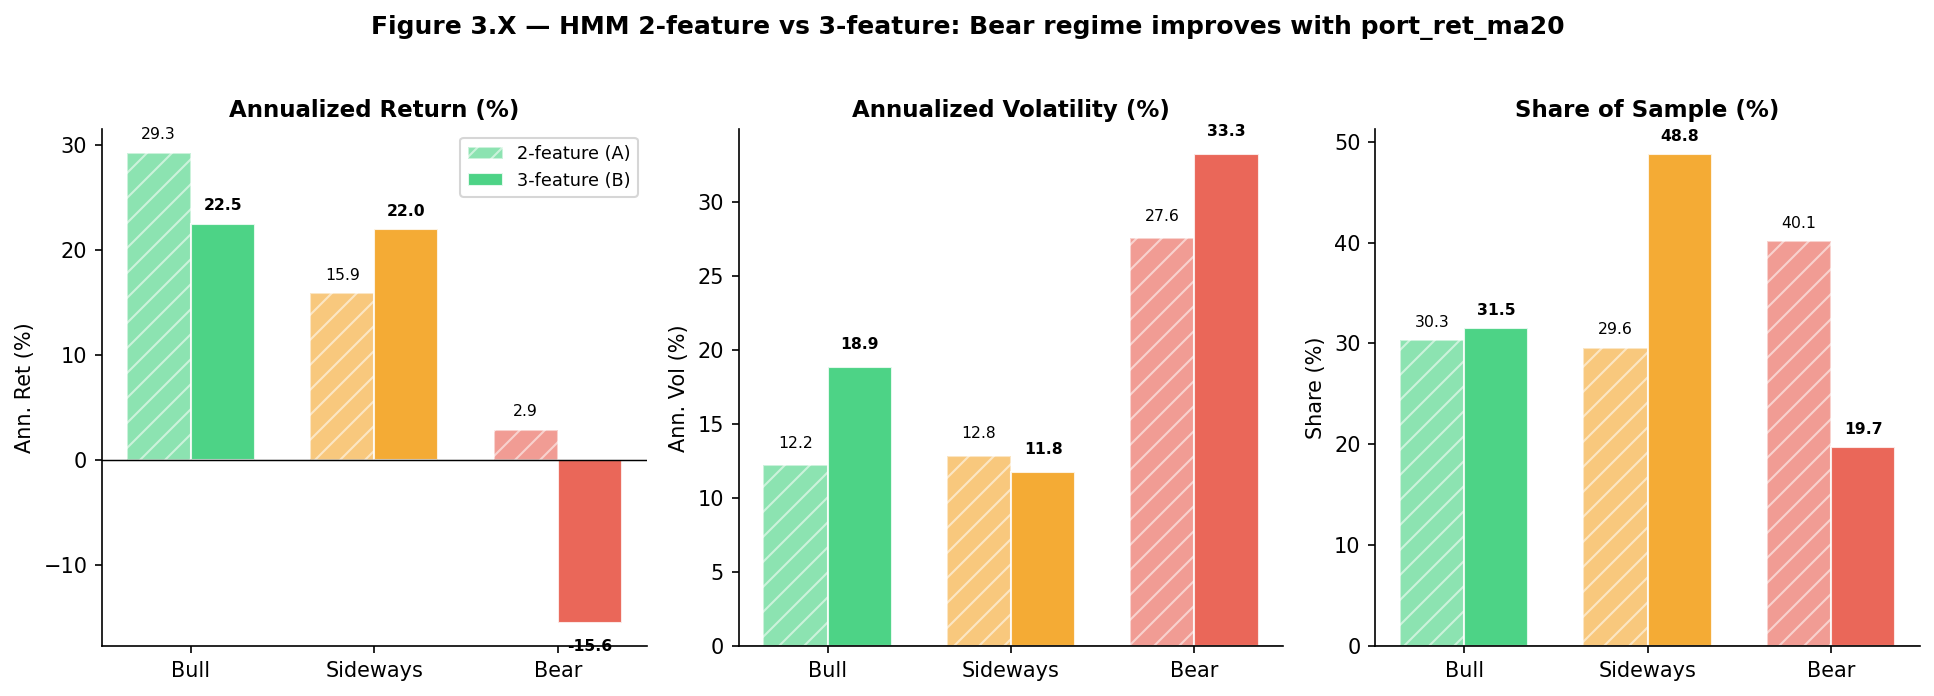

In [12]:
# Bar chart: Bear return comparison
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

metrics = ['Ann. Ret (%)', 'Ann. Vol (%)', 'Share (%)']
metric_titles = ['Annualized Return (%)', 'Annualized Volatility (%)', 'Share of Sample (%)']
bar_colors = {'Bull': REGIME_COLORS['Bull'], 'Sideways': REGIME_COLORS['Sideways'], 'Bear': REGIME_COLORS['Bear']}

for ax, metric, title in zip(axes, metrics, metric_titles):
    x = np.arange(3)
    w = 0.35
    labels = ['Bull', 'Sideways', 'Bear']
    vals_2 = [stats_2feat.loc[stats_2feat['Regime'] == l, metric].iloc[0] for l in labels]
    vals_3 = [stats_3feat.loc[stats_3feat['Regime'] == l, metric].iloc[0] for l in labels]
    
    b1 = ax.bar(x - w/2, vals_2, w, label='2-feature (A)', color=[bar_colors[l] for l in labels],
                alpha=0.55, edgecolor='white', hatch='//')
    b2 = ax.bar(x + w/2, vals_3, w, label='3-feature (B)', color=[bar_colors[l] for l in labels],
                alpha=0.85, edgecolor='white')
    
    ax.axhline(0, color='black', linewidth=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel(metric)
    if ax == axes[0]:
        ax.legend(fontsize=8.5)
    
    # Annotate values
    for xi, (v2, v3) in enumerate(zip(vals_2, vals_3)):
        ax.text(xi - w/2, v2 + (1 if v2 >= 0 else -1.5), f'{v2:.1f}',
                ha='center', va='bottom' if v2 >= 0 else 'top', fontsize=7.5)
        ax.text(xi + w/2, v3 + (1 if v3 >= 0 else -1.5), f'{v3:.1f}',
                ha='center', va='bottom' if v3 >= 0 else 'top', fontsize=7.5, fontweight='bold')

fig.suptitle(
    'Figure 3.X — HMM 2-feature vs 3-feature: Bear regime improves with port_ret_ma20',
    fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_hmm_ab_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 7 · Regime Timeline for Individual Tickers
*(Show regime labels overlaid on actual stock price)*

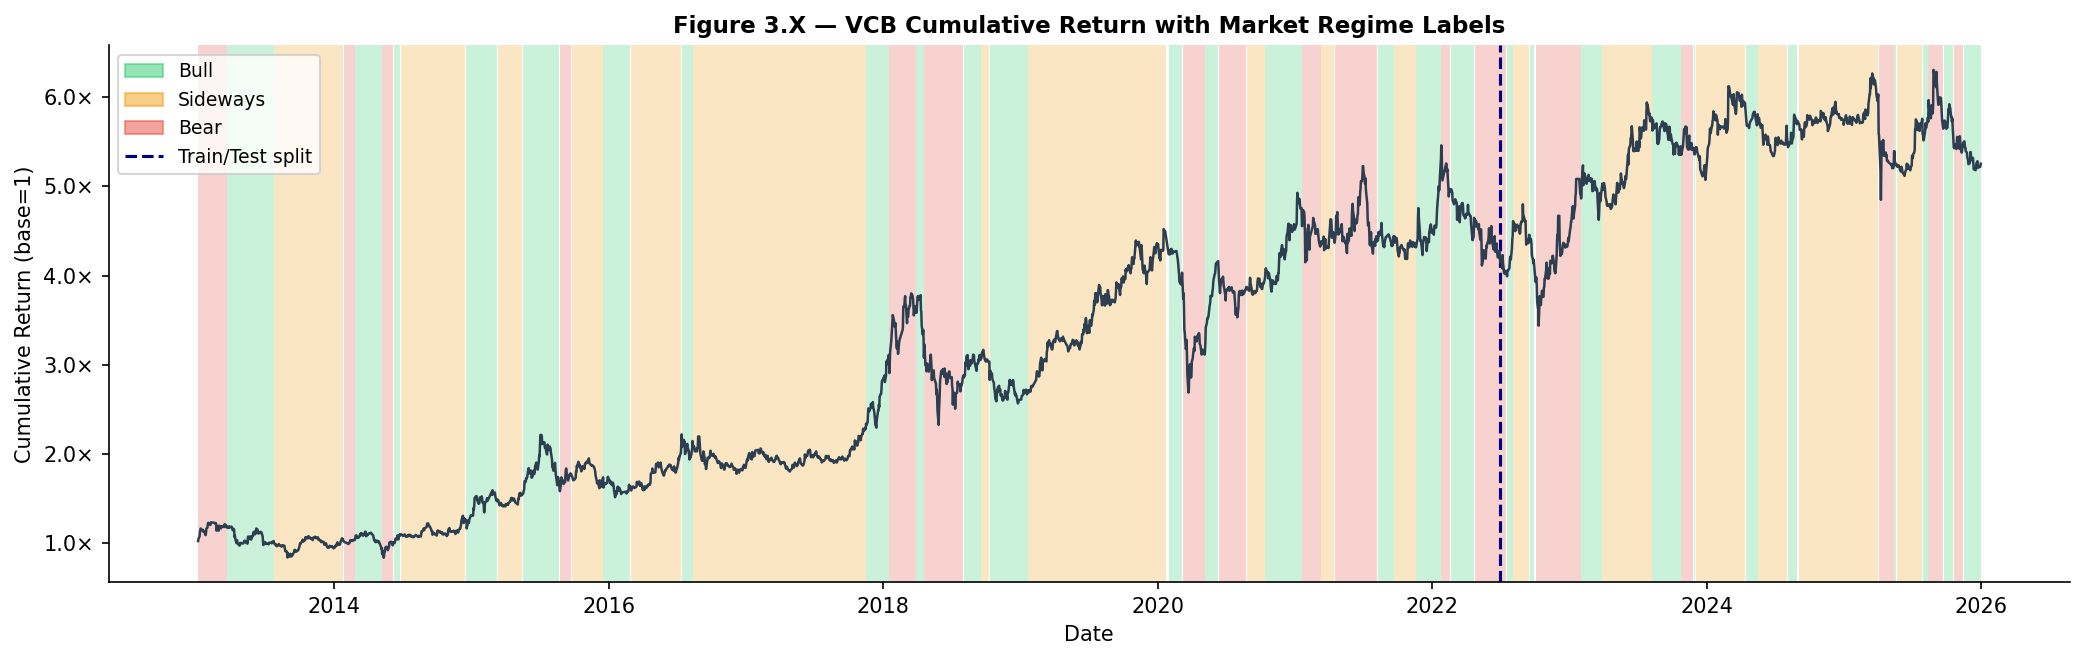

In [13]:
TICKER = 'VCB'  # Change to any VN30 ticker: ACB, BVH, CTG, MBB, etc.

# Get per-ticker price (use ret_1d to reconstruct index or load raw)
tick_df = df[df['ticker'] == TICKER][['Date', 'ret_1d']].set_index('Date').sort_index()
tick_df['cum_ret'] = (1 + tick_df['ret_1d']).cumprod()

# Merge regime onto ticker data
tick_regime = tick_df.join(port[['regime']], how='left')
tick_regime['regime'] = tick_regime['regime'].ffill().bfill()

fig, ax = plt.subplots(figsize=(14, 4.5))
shade_regimes(ax, tick_regime, col='regime')
ax.plot(tick_regime.index, tick_regime['cum_ret'], color='#2c3e50', linewidth=1.2, zorder=5)
ax.axvline(pd.Timestamp(TRAIN_END), color='navy', linewidth=1.5, linestyle='--')

patches = [mpatches.Patch(color=REGIME_COLORS[l], alpha=0.5, label=l)
           for l in ['Bull', 'Sideways', 'Bear']]
ax.legend(handles=patches + [plt.Line2D([0],[0],color='navy',linestyle='--',label='Train/Test split')],
          loc='upper left')
ax.set_title(f'Figure 3.X — {TICKER} Cumulative Return with Market Regime Labels', fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Return (base=1)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:.1f}×'))

plt.tight_layout()
plt.savefig(FIG_DIR / f'fig_regime_{TICKER}.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 8 · Special Events Deep-Dive

In [14]:
EVENTS = {
    'COVID Crash':      ('2020-02-15', '2020-04-30'),
    'COVID Recovery':   ('2020-05-01', '2020-09-30'),
    'Bull Run 2021':    ('2021-01-01', '2021-12-31'),
    'Bond Crisis 2022': ('2022-09-01', '2022-12-31'),
}

print(f' {"Event":<22s}  {"Date Range":<25s}  {"Bull%":>6s}  {"Sideways%":>9s}  {"Bear%":>6s}  {"Dominant"}')
print('-' * 80)
for ev, (s, e) in EVENTS.items():
    sub = port.loc[s:e, 'regime']
    if len(sub) == 0:
        continue
    vc = sub.value_counts(normalize=True) * 100
    bull_p  = vc.get('Bull',     0)
    side_p  = vc.get('Sideways', 0)
    bear_p  = vc.get('Bear',     0)
    dom = vc.index[0]
    print(f'{ev:<22s}  {s} → {e[:7]}  {bull_p:>6.1f}%  {side_p:>9.1f}%  {bear_p:>6.1f}%  {dom}')

 Event                   Date Range                  Bull%  Sideways%   Bear%  Dominant
--------------------------------------------------------------------------------
COVID Crash             2020-02-15 → 2020-04    28.8%        0.0%    71.2%  Bear
COVID Recovery          2020-05-01 → 2020-09    24.3%       24.3%    51.4%  Bear
Bull Run 2021           2021-01-01 → 2021-12    28.8%       26.8%    44.4%  Bear
Bond Crisis 2022        2022-09-01 → 2022-12    11.8%       11.8%    76.5%  Bear


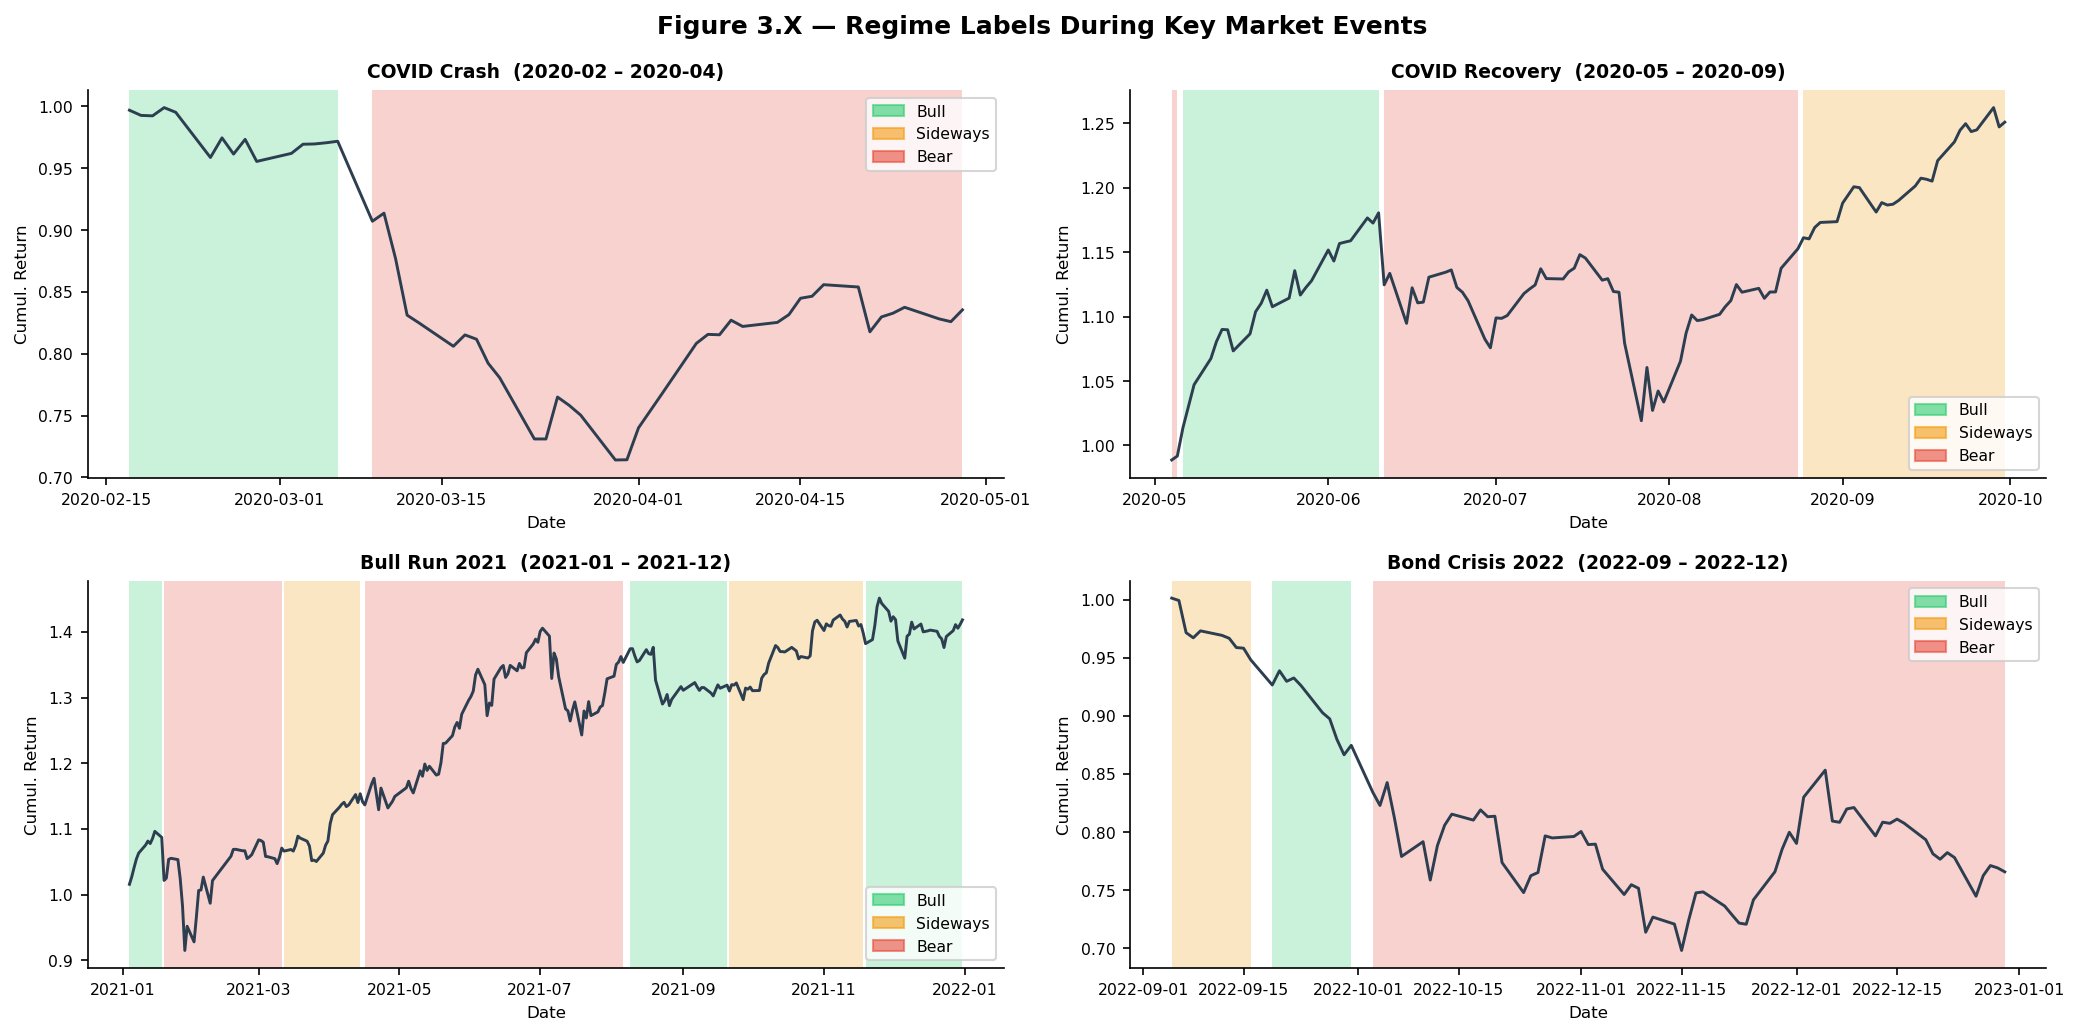

In [15]:
# Zoom-in plot for special events
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharey=False)

for ax, (ev, (s, e)) in zip(axes.flat, EVENTS.items()):
    sub = port.loc[s:e].copy()
    if len(sub) == 0:
        ax.set_visible(False)
        continue
    shade_regimes(ax, sub)
    ax.plot(sub.index, (1 + sub['port_ret']).cumprod(), color='#2c3e50', linewidth=1.4)
    
    patches = [mpatches.Patch(color=REGIME_COLORS[l], alpha=0.6, label=l)
               for l in ['Bull', 'Sideways', 'Bear']]
    ax.legend(handles=patches, loc='best', fontsize=7.5)
    ax.set_title(f'{ev}  ({s[:7]} – {e[:7]})', fontweight='bold', fontsize=9)
    ax.set_xlabel('Date', fontsize=8)
    ax.set_ylabel('Cumul. Return', fontsize=8)
    ax.tick_params(labelsize=7.5)

fig.suptitle('Figure 3.X — Regime Labels During Key Market Events', fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_regime_events.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Summary

| Figure | File | Use in paper |
|--------|------|--------------|
| Table 3.X | `table_regime_stats.png` | Regime characteristics (return, vol, Sharpe) |
| Figure 3.X | `fig_regime_timeline.png` | Full timeline with regime shading |
| Figure 3.X | `fig_regime_yearly.png` | Annual distribution stacked bar |
| Figure 3.X | `fig_regime_return_dist.png` | Return distribution per regime |
| Figure 3.X | `fig_regime_transition.png` | Transition matrix (regime persistence) |
| Figure 3.X | `fig_hmm_ab_comparison.png` | A/B comparison: 2-feat vs 3-feat HMM |
| Figure 3.X | `fig_regime_VCB.png` | Ticker-level regime overlay |
| Figure 3.X | `fig_regime_events.png` | Special events deep-dive |

All figures saved to `notebooks/eda/figures/`